# Yosemite Valley flyover, step by step

How the 73-second flight through Yosemite Valley was made with [forge3d](https://github.com/milos-agathon/forge3d) 1.40.1, using the project's own scripts (`scripts/config.py`, `prep.py`, `flight.py`, `render.py`):

1. The terrain: 1 m lidar averaged to 3 m, and what the viewer actually meshes
2. The granite trick: why aerial photos fail on cliffs, and the fix
3. The flight: keyframes, speeds, lenses, and keeping clear of the walls
4. The evening Sun
5. Frames from the flight, straight from forge3d and then finished

## Setup

Run `pixi run data` and `pixi run prep` first: this notebook reads the prepared DEM and imagery in `data/`. Sections 1–4 need no renderer; section 5 opens forge3d's viewer (a GPU, or on Linux Mesa's software Vulkan under `xvfb-run`).

In [1]:
WIDTH = 960          # frame width for section 5 (16:9); the film is 1920
LITE = True          # lighter shadows and antialiasing (render.py --lite): much faster on a CPU
RENDER = True        # False skips section 5
STILLS = [0.0, 27.7, 42.5, 69.8]   # seconds into the flight: Half Dome, El Cap gap, Tunnel View, the hold

In [2]:
import math, sys, time
from pathlib import Path

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import matplotlib.patheffects as pe
from PIL import Image
from scipy import ndimage

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "config.py").exists())
sys.path.insert(0, str(ROOT / "scripts"))
import config, prep, flight
import forge3d as f3d

%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"pil_kwargs": {"quality": 85}, "bbox_inches": "tight"}
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})
Image.MAX_IMAGE_PIXELS = None
print("forge3d", f3d.__version__)

PLACES = {"Half Dome": (37.7459, -119.5332), "El Capitan": (37.7342, -119.6378),
          "Yosemite Falls": (37.7566, -119.5969), "Bridalveil Fall": (37.7166, -119.6463),
          "Tunnel View": (37.7156, -119.6772), "Sentinel Bridge": (37.7425, -119.5890),
          "Cathedral Rocks": (37.7146, -119.6368), "Clouds Rest": (37.7676, -119.4895)}
def utm(lat, lon):
    x, y = flight.to_utm(lat, lon)
    return float(x[0]), float(y[0])

forge3d 1.40.1


## 1. The terrain

The DEM is the Yosemite National Park 2019 lidar survey (USGS 3DEP, 1 m), averaged to 3 m over a 23 × 12.6 km box from west of Tunnel View to past Clouds Rest, with the 10 m 3DEP product filling anything the lidar misses. `prep.py` gives it a blur of less than a pixel, so single noisy cells don't become spikes.

DEM 7680 x 4200 cells at 3 m = 23.0 x 12.6 km, 1042-3026 m


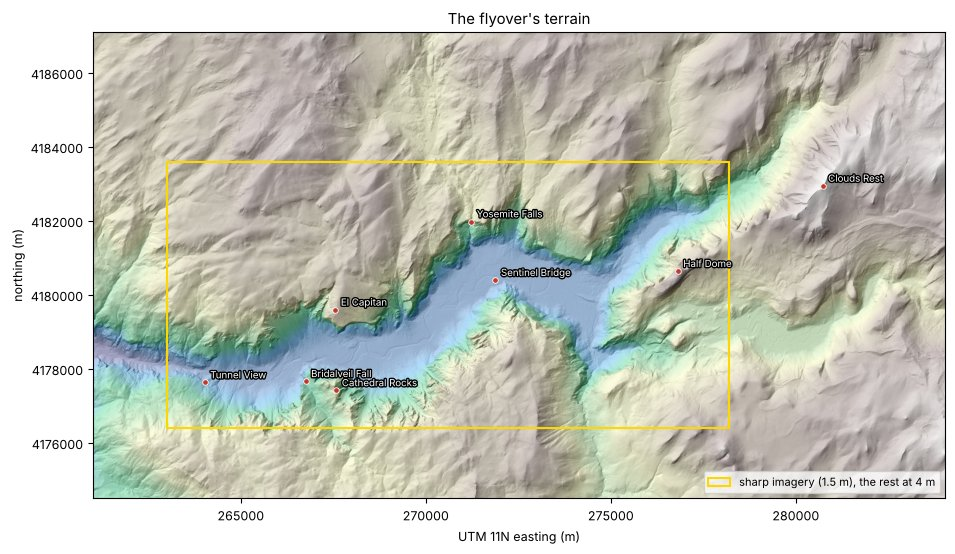

In [3]:
with rasterio.open(config.DEM) as src:
    dem = src.read(1)
k = 4
z = dem[::k, ::k]
print(f"DEM {dem.shape[1]} x {dem.shape[0]} cells at {config.DEM_RES:g} m = "
      f"{(config.RIGHT - config.LEFT) / 1000:.1f} x {(config.TOP - config.BOTTOM) / 1000:.1f} km, "
      f"{dem.min():.0f}-{dem.max():.0f} m")
ext = (config.LEFT, config.RIGHT, config.BOTTOM, config.TOP)
shade = LightSource(azdeg=315, altdeg=40).hillshade(z, vert_exag=1.5, dx=config.DEM_RES * k, dy=config.DEM_RES * k)

def base_map(ax):
    ax.imshow(shade, cmap="gray", extent=ext)
    ax.imshow(z, cmap="terrain", alpha=0.3, extent=ext)
    for name, (la, lo) in PLACES.items():
        x, y = utm(la, lo)
        ax.plot(x, y, "o", ms=4, color="#c0392b", mec="white", mew=0.6)
        ax.annotate(name, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=7, color="white",
                    path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.set_xlabel("UTM 11N easting (m)"); ax.set_ylabel("northing (m)")

fig, ax = plt.subplots(figsize=(11, 6.2))
base_map(ax)
l, t, r, b = config.VALLEY
ax.add_patch(plt.Rectangle((l, b), r - l, t - b, fill=False, ec="gold", lw=1.5,
                           label=f"sharp imagery ({config.VALLEY_RES:g} m), the rest at {config.CONTEXT_RES:g} m"))
ax.legend(loc="lower right", fontsize=8); ax.set_title("The flyover's terrain")
plt.show()

**What the viewer actually meshes.** forge3d's terrain viewer builds a square mesh at most 2048 vertices on a side (its log says `grid=2048x2048` for this DEM) and point-samples a bigger DEM to fit. This DEM is 7680 × 4200 cells, so in the film the vertices are about 11 m apart east–west and 6 m north–south, not 3 m. Close up on El Capitan, that looks like this:

a 2048 x 2048 mesh over 23.0 x 12.6 km: a vertex every 11.3 m east-west and 6.2 m north-south (the 3 m DEM is sampled every 3.8 and 2.1 cells)


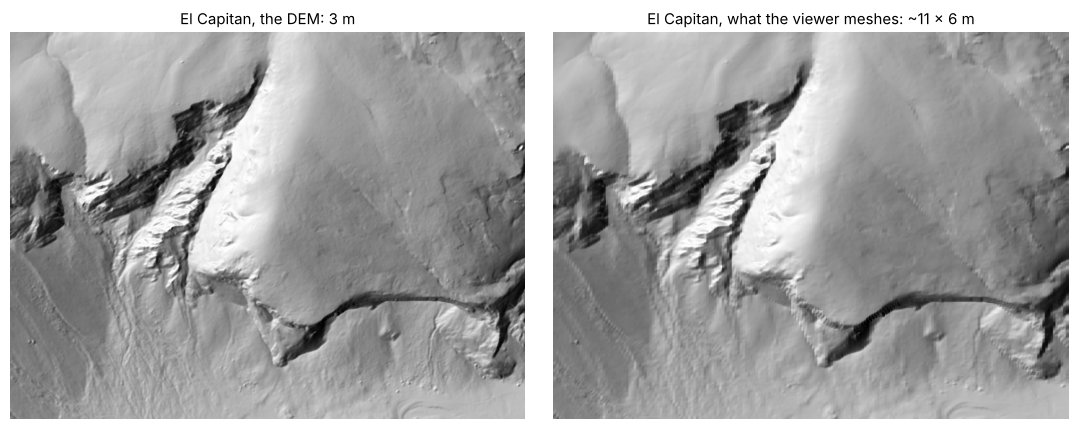

In [4]:
span, tall = config.RIGHT - config.LEFT, config.TOP - config.BOTTOM
step, step_ns = span / 2047, tall / 2047
print(f"a 2048 x 2048 mesh over {span / 1000:.1f} x {tall / 1000:.1f} km: a vertex every {step:.1f} m east-west and "
      f"{step_ns:.1f} m north-south (the 3 m DEM is sampled every {step / config.DEM_RES:.1f} and {step_ns / config.DEM_RES:.1f} cells)")

ex, ey = utm(*PLACES["El Capitan"])
r0 = int((config.TOP - (ey + 900)) / config.DEM_RES); c0 = int((ex - 1200 - config.LEFT) / config.DEM_RES)
crop = dem[r0:r0 + 600, c0:c0 + 800]                                  # 2.4 x 1.8 km
n = int(round(step / config.DEM_RES))
n_ns = int(round(step_ns / config.DEM_RES))
coarse = ndimage.zoom(crop[::n_ns, ::n], (n_ns, n), order=1)[:crop.shape[0], :crop.shape[1]]   # point-sampled, then a smooth mesh between
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, a, title in ((axs[0], crop, "the DEM: 3 m"), (axs[1], coarse, f"what the viewer meshes: ~{step:.0f} x {step_ns:.0f} m")):
    ax.imshow(LightSource(azdeg=300, altdeg=30).hillshade(a, dx=config.DEM_RES, dy=config.DEM_RES), cmap="gray")
    ax.set_title(f"El Capitan, {title}"); ax.axis("off")
plt.tight_layout(); plt.show()

That's the one big limit of this film, and the reason SOLSTICE renders each frame as nested layers, each window small enough to stay under the cap. For Yosemite the trick that does the most work is the colour, not the mesh.

## 2. The granite trick

NAIP aerial photos are shot from straight above around midday. On a 900 m wall that's a disaster: the whole face is a few pixels wide, smeared, and usually in shadow. Draped on a 3D cliff, it paints El Capitan dark grey-green.

`prep.py` fixes it with the slope. Faces steeper than about 50° (a smooth blend from 42° to 62°) get a sunlit granite colour, keeping a little of the photo's light and dark so it isn't flat paint; then the evening sun in the renderer does the shading. Here it is on the east half of the valley imagery:

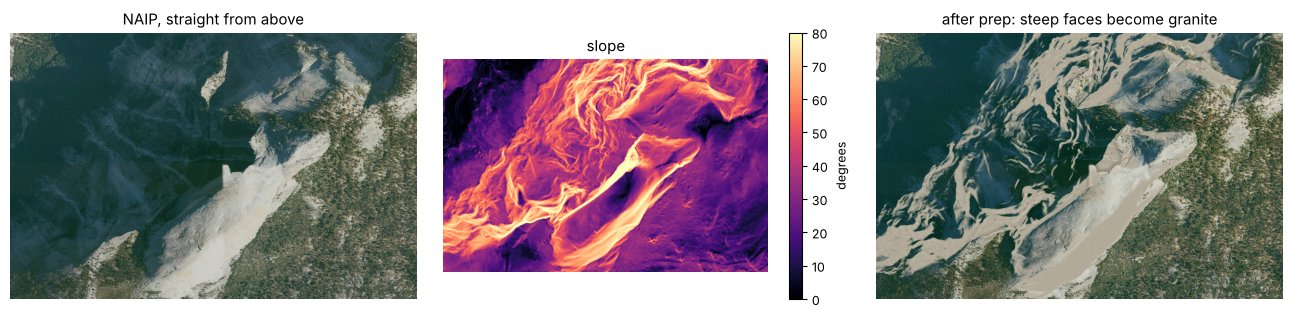

in this window, 12% of the ground is steeper than 62° (fully granite), 22% is in the blend


In [5]:
slope = prep.slope_deg()
for p_, l_, t_, r_, b_ in config.valley_halves():
    if p_ == config.NAIP_EAST:
        east_box = (l_, t_, r_, b_)
raw_p, grd_p = config.NAIP_EAST, config.graded(config.NAIP_EAST)
# a window around Half Dome's face, in image pixels
hx, hy = utm(*PLACES["Half Dome"])
l_, t_, r_, b_ = east_box
col = int((hx - 1500 - l_) / config.VALLEY_RES); row = int((t_ - (hy + 900)) / config.VALLEY_RES)
w_, h_ = int(2600 / config.VALLEY_RES), int(1700 / config.VALLEY_RES)
box = (max(col, 0), max(row, 0), max(col, 0) + w_, max(row, 0) + h_)
raw = Image.open(raw_p).crop(box)
grd = Image.open(grd_p).crop(box)
# the slope on the same window
x0 = l_ + box[0] * config.VALLEY_RES; y0 = t_ - box[1] * config.VALLEY_RES
rr = int((config.TOP - y0) / config.DEM_RES); cc = int((x0 - config.LEFT) / config.DEM_RES)
sl = slope[rr:rr + int(h_ * config.VALLEY_RES / config.DEM_RES), cc:cc + int(w_ * config.VALLEY_RES / config.DEM_RES)]

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].imshow(raw); axs[0].set_title("NAIP, straight from above")
im = axs[1].imshow(sl, cmap="magma", vmin=0, vmax=80); axs[1].set_title("slope")
plt.colorbar(im, ax=axs[1], shrink=0.8, label="degrees")
axs[2].imshow(grd); axs[2].set_title("after prep: steep faces become granite")
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()
steep = (sl > prep.CLIFF_DEG[1]).mean()
print(f"in this window, {steep:.0%} of the ground is steeper than {prep.CLIFF_DEG[1]:g}° (fully granite), "
      f"{((sl > prep.CLIFF_DEG[0]) & (sl <= prep.CLIFF_DEG[1])).mean():.0%} is in the blend")

## 3. The flight

The path is fifteen keyframes in `flight.KEYS`: an eye point and an aim point (latitude, longitude, altitude), the speed through that point, and the lens. The eye follows a Catmull-Rom spline through its points; the timing comes from the speeds (each stretch takes its length divided by the average of its two speeds), and a monotone spline turns time into distance along the path, so the camera speeds up and slows down smoothly and never backs up. The aim and the lens glide between their keyframes the same way. At the end there's a 3-second hold on Half Dome.

Then the path is checked against the terrain: wherever the eye would come within 110 m of the highest ground within 150 m of it, it's lifted, and the lift is spread over a couple of seconds so the camera doesn't hop.

In [6]:
f = flight.plan(dem)
flight.report(f)

2185 frames, 73 s at 30 fps
    0.0 s  facing Half Dome          75 m/s  lens  48    882 m up
    6.7 s  along the face           220 m/s  lens  50    315 m up
   10.1 s  into the valley          345 m/s  lens  52    554 m up
   12.0 s  Curry Village            419 m/s  lens  50    394 m up
   16.1 s  Sentinel Bridge          458 m/s  lens  50    380 m up
   21.4 s  Leidig Meadow            455 m/s  lens  50    372 m up
   27.7 s  El Cap / Cathedral       434 m/s  lens  50    373 m up
   32.4 s  Bridalveil Meadow        387 m/s  lens  50    375 m up
   36.2 s  into the turn            317 m/s  lens  50    354 m up
   39.5 s  turning                  220 m/s  lens  44    238 m up
   42.5 s  Tunnel View              172 m/s  lens  30    210 m up
   45.6 s  Tunnel View, easing      218 m/s  lens  34    304 m up
   54.7 s  back up the valley       396 m/s  lens  42    435 m up
   63.4 s  Leidig Meadow            181 m/s  lens  34    313 m up
   69.8 s  Sentinel Bridge, hold      0 m/s  len

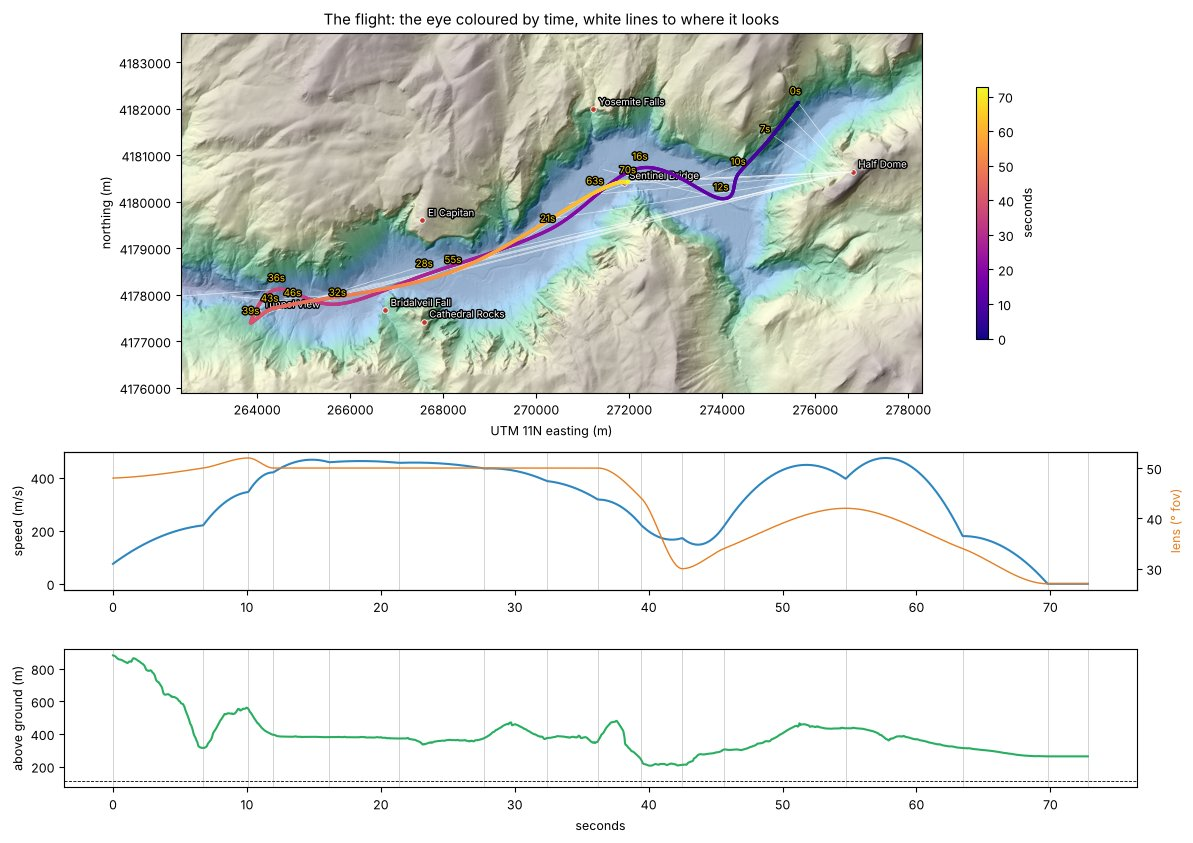

In [7]:
fig = plt.figure(figsize=(12, 8.5))
gs = fig.add_gridspec(3, 1, height_ratios=[2.6, 1, 1])
ax = fig.add_subplot(gs[0]); base_map(ax)
sc = ax.scatter(f.eye[:, 0], f.eye[:, 1], c=f.t, cmap="plasma", s=2, zorder=3)
for i in range(0, len(f.t), flight.FPS * 3):
    ax.plot([f.eye[i, 0], f.aim[i, 0]], [f.eye[i, 1], f.aim[i, 1]], color="white", lw=0.5, alpha=0.7)
for t0, kk in zip(f.key_t, flight.KEYS):
    i = min(int(round(t0 * flight.FPS)), len(f.t) - 1)
    ax.annotate(f"{t0:.0f}s", f.eye[i, :2], xytext=(-6, 6), textcoords="offset points", fontsize=7, color="gold",
                path_effects=[pe.withStroke(linewidth=2, foreground="black")])
pad = 1500
ax.set_xlim(f.eye[:, 0].min() - pad, max(f.eye[:, 0].max(), f.aim[:, 0].max()) + pad)
ax.set_ylim(f.eye[:, 1].min() - pad, f.eye[:, 1].max() + pad)
plt.colorbar(sc, ax=ax, shrink=0.7, label="seconds"); ax.set_title("The flight: the eye coloured by time, white lines to where it looks")

a2 = fig.add_subplot(gs[1]); a2.plot(f.t, f.speed, color="#2e86c1"); a2.set_ylabel("speed (m/s)")
a2b = a2.twinx(); a2b.plot(f.t, f.fov, color="#e67e22", lw=1); a2b.set_ylabel("lens (° fov)", color="#e67e22")
a3 = fig.add_subplot(gs[2], sharex=a2); a3.plot(f.t, f.clearance, color="#27ae60")
a3.axhline(flight.MIN_CLEARANCE, color="k", lw=0.6, ls="--"); a3.set_ylabel("above ground (m)"); a3.set_xlabel("seconds")
for a in (a2, a3):
    for t0 in f.key_t: a.axvline(t0, color="grey", lw=0.4, alpha=0.6)
plt.tight_layout(); plt.show()

## 4. The evening Sun

The light is a real one: the Sun over the valley on 20 June 2026 at 7:15 pm PDT, from `forge3d.sun_position_utc`. Low in the west-north-west, it lights Half Dome's north-west face head-on while the valley floor drops into shade, which is exactly the face the flight starts on.

Sun at 19:15 PDT on June 20: azimuth 291.0°, 11.3° up


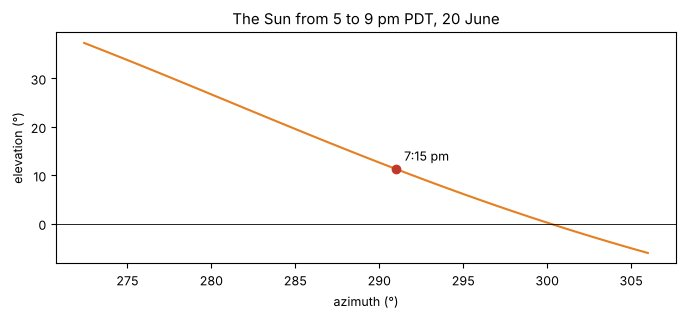

In [8]:
sun = f3d.sun_position_utc(*config.SUN_LATLON, *config.SUN_UTC)
print(f"Sun at {config.SUN_UTC[3] - 7 + 24:02d}:{config.SUN_UTC[4]:02d} PDT on June 20: azimuth {sun.azimuth:.1f}°, {sun.elevation:.1f}° up")
from datetime import datetime, timedelta, timezone
t0 = datetime(2026, 6, 21, 0, 0, tzinfo=timezone.utc)                      # 5 pm PDT
ts = [t0 + timedelta(minutes=m) for m in range(0, 4 * 60, 5)]
ae = np.array([[s.azimuth, s.elevation] for s in (f3d.sun_position_utc(*config.SUN_LATLON, t.year, t.month, t.day, t.hour, t.minute, 0) for t in ts)])
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ae[:, 0], ae[:, 1], color="#e67e22"); ax.plot(sun.azimuth, sun.elevation, "o", color="#c0392b")
ax.annotate("7:15 pm", (sun.azimuth, sun.elevation), xytext=(6, 6), textcoords="offset points")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("azimuth (°)"); ax.set_ylabel("elevation (°)")
ax.set_title("The Sun from 5 to 9 pm PDT, 20 June"); plt.show()

## 5. Frames from the flight

One forge3d viewer holds the whole scene: the 3 m DEM, the 4 m context imagery as one overlay and the two 1.5 m valley halves on top of it, and PBR shading with height-based ambient occlusion and soft sun visibility. The film uses a 4096² shadow map with soft PCSS shadows and 8× antialiasing; with `LITE` on (as here, to keep a CPU run to a couple of minutes) it's the preview's 2048² map, PCF shadows and 4×. For each frame the camera is set from the flight (`flight.camera` turns an eye and an aim into the viewer's orbit camera) and the viewer takes a snapshot.

`render.finish` then gives every frame the evening look: it finds the viewer's plain background (a smooth near-white region touching the top edge), paints a sky gradient into it, warms the highlights and cools the shadows, and adds haze along the skyline.

In [9]:
if RENDER:
    import render as R
    size = (WIDTH, WIDTH * 9 // 16)
    min_h = float(dem.min())
    out = config.OUT / "notebook"; out.mkdir(parents=True, exist_ok=True)
    pbr = dict(R.PBR, **R.LITE) if LITE else dict(R.PBR)
    frames = [min(int(round(s * flight.FPS)), len(f.t) - 1) for s in STILLS]
    t0 = time.time()
    v = R.open_viewer(out / "viewer.log", width=size[0], height=size[1], terrain_path=str(config.DEM),
                      fov_deg=flight.FOV, title="Yosemite Valley")
    shots = []
    try:
        v.load_overlay("context", config.graded(config.NAIP_CONTEXT), extent=(0, 0, 1, 1), z_order=0)
        for j, (p_, l_, t_, r_, b_) in enumerate(config.valley_halves()):
            v.load_overlay(f"valley_{j}", config.graded(p_), extent=R.uv(l_, t_, r_, b_), z_order=1 + j)
        v.send_ipc({"cmd": "set_terrain_sun", "azimuth_deg": float(sun.azimuth), "elevation_deg": float(sun.elevation), "intensity": 1.0})
        v.send_ipc({"cmd": "set_terrain_pbr", **pbr})
        v.send_ipc({"cmd": "set_terrain", **R.TERRAIN})
        v.send_ipc(flight.camera(f.eye[frames[0]], f.aim[frames[0]], min_h, float(f.fov[frames[0]])))
        time.sleep(2.0)
        for i in frames:
            v.send_ipc(flight.camera(f.eye[i], f.aim[i], min_h, float(f.fov[i])))
            p = out / f"raw_{f.t[i]:05.1f}s.png"
            v.snapshot(p, *size)
            shots.append((i, p))
    finally:
        v.close()
    print(f"{len(shots)} frames in {time.time() - t0:.0f} s")

4 frames in 150 s


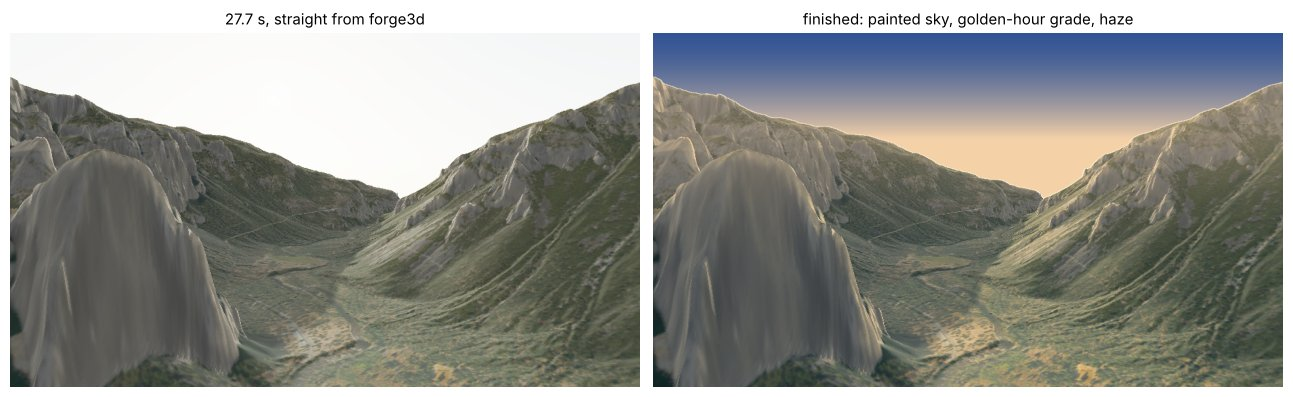

In [10]:
if RENDER:
    i, p = shots[1]
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.9))
    axs[0].imshow(Image.open(p)); axs[0].set_title(f"{f.t[i]:.1f} s, straight from forge3d")
    axs[1].imshow(R.finish(p)); axs[1].set_title("finished: painted sky, golden-hour grade, haze")
    for ax in axs: ax.axis("off")
    plt.tight_layout(); plt.show()

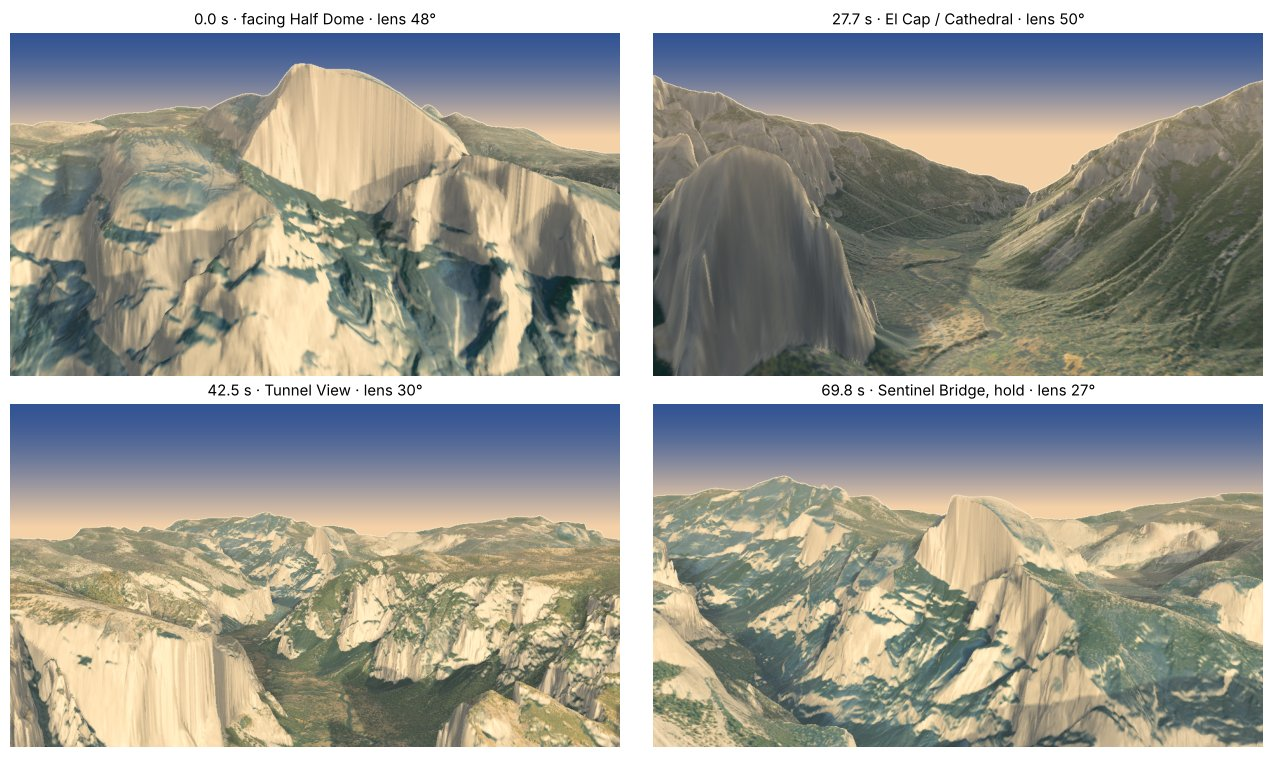

In [11]:
if RENDER:
    names = {round(t0, 1): kk[4] for t0, kk in zip(f.key_t, flight.KEYS)}
    fig, axs = plt.subplots(2, 2, figsize=(13, 7.6))
    for ax, (i, p) in zip(axs.ravel(), shots):
        ax.imshow(R.finish(p)); ax.axis("off")
        near = min(names, key=lambda t0: abs(t0 - f.t[i]))
        ax.set_title(f"{f.t[i]:.1f} s · {names[near] if abs(near - f.t[i]) < 1 else ''} · lens {f.fov[i]:.0f}°")
    plt.tight_layout(); plt.show()

The whole film is `pixi run render`: 2,185 frames at 1920 × 1080, piped straight from the viewer into ffmpeg (`out/yosemite_valley_flyover.mp4`).

**Where it goes next.** The coarse mesh in section 1 is the thing to beat. SOLSTICE renders every frame as a stack of layers (the whole area coarse for the horizon, then windows of a few kilometres and then a few hundred metres around the camera, each under the 2048 cap), and composites them. Done here, it would put real 1 m lidar on El Capitan's face.

Data: USGS 3DEP lidar (CA_YosemiteNP_2019) and 1/3 arc-second DEM; USDA NAIP via the USGS National Map. Rendering: [forge3d](https://github.com/milos-agathon/forge3d) by Milos Popovic.